# 使用大语言模型的创意文本情感分析（二）
## 文学作品的情感轨迹：朱自清《背影》（课后作业 · 程序4）

> **课程**：第四讲　感知世界：识别与理解文本中的情感
> **作业要求**：完成"使用大语言模型的创意文本情感分析（程序3和程序4）"
> **完成人**：（学习者本人）

### 任务（按 PPT 的四步）

1. 读取 `背影.txt`，按句号、感叹号分句，并给句子编号；
2. 用大语言模型提取每句话中的**情感词**（或隐含的情感实体）；
3. 用大语言模型给每句话打**情感分**（$-1 \sim +1$）；
4. 画出**情感轨迹图**：横坐标是句子序号，纵坐标是情感得分，散点标签是情感词，虚线把它们连起来。

> 本程序在讲义的基础上补全了"情感轨迹图 + 分段解读 + 与 SnowNLP 的对比"，
> 并对"大模型读文学"这件事做了自己的分析。

## 0. 运行说明

与程序 3 相同：配置 `DEEPSEEK_API_KEY` 后把 `USE_API=True` 即可**实时调用**模型；
本机没有 Key，因此读取上一次大模型运行结果的缓存 `程序4_背影_大模型结果.json`（58 句，逐句"情感词 + 情感值"）。

In [1]:
import os, re, json, time
import pandas as pd

API_KEY = os.environ.get("DEEPSEEK_API_KEY", "").strip()
USE_API = bool(API_KEY)
API_URL = "https://api.deepseek.com/chat/completions"
MODEL = "deepseek-chat"
CACHE = "程序4_背影_大模型结果.json"

print("USE_API =", USE_API, "（False 时读取本地缓存）")

USE_API = False （False 时读取本地缓存）


## 1. 读取文本并分句

按句号 `。`、感叹号 `！` 断句（保留标点），去掉空白句后编号。

In [2]:
with open("背影.txt", "r", encoding="utf-8") as f:
    text = f.read()

sentences = re.split(r"(?<=[。！])", text)
sentences = [s.strip() for s in sentences if s.strip()]
numbered_sentences = [(i + 1, s) for i, s in enumerate(sentences)]

print("共分句：", len(numbered_sentences))
for num, sent in numbered_sentences:
    print(f"{num:02d}: {sent}")

共分句： 58
01: 我与父亲不相见已二年余了，我最不能忘记的是他的背影。
02: 那年冬天，祖母死了，父亲的差使也交卸了，正是祸不单行的日子。
03: 我从北京到徐州，打算跟着父亲奔丧回家。
04: 到徐州见着父亲，看见满院狼藉的东西，又想起祖母，不禁簌簌地流下眼泪。
05: 父亲说：“事已如此，不必难过，好在天无绝人之路！
06: ”
回家变卖典质，父亲还了亏空；又借钱办了丧事。
07: 这些日子，家中光景很是惨澹，一半为了丧事，一半为了父亲赋闲。
08: 丧事完毕，父亲要到南京谋事，我也要回北京念书，我们便同行。
09: 到南京时，有朋友约去游逛，勾留了一日；第二日上午便须渡江到浦口，下午上车北去。
10: 父亲因为事忙，本已说定不送我，叫旅馆里一个熟识的茶房陪我同去。
11: 他再三嘱咐茶房，甚是仔细。
12: 但他终于不放心，怕茶房不妥帖；颇踌躇了一会。
13: 其实我那年已二十岁，北京已来往过两三次，是没有什么要紧的了。
14: 他踌躇了一会，终于决定还是自己送我去。
15: 我再三劝他不必去；他只说：“不要紧，他们去不好！
16: ”
我们过了江，进了车站。
17: 我买票，他忙着照看行李。
18: 行李太多了，得向脚夫⑾行些小费才可过去。
19: 他便又忙着和他们讲价钱。
20: 我那时真是聪明过分，总觉他说话不大漂亮，非自己插嘴不可，但他终于讲定了价钱；就送我上车。
21: 他给我拣定了靠车门的一张椅子；我将他给我做的紫毛大衣铺好座位。
22: 他嘱我路上小心，夜里要警醒些，不要受凉。
23: 又嘱托茶房好好照应我。
24: 我心里暗笑他的迂；他们只认得钱，托他们只是白托！
25: 而且我这样大年纪的人，难道还不能料理自己么？我现在想想，我那时真是太聪明了。
26: 我说道：“爸爸，你走吧。
27: ”他往车外看了看，说：“我买几个橘子去。
28: 你就在此地，不要走动。
29: ”我看那边月台的栅栏外有几个卖东西的等着顾客。
30: 走到那边月台，须穿过铁道，须跳下去又爬上去。
31: 父亲是一个胖子，走过去自然要费事些。
32: 我本来要去的，他不肯，只好让他去。
33: 我看见他戴着黑布小帽，穿着黑布大马褂，深青布棉袍，蹒跚⒀地走到铁道边，慢慢探身下去，尚不大难。
34: 可是他穿过铁道，要爬上那边月台，就不容易了。
35: 他用两手攀着上

> 说明：讲义的分句规则会把句末的右引号 `”` 留在下一句开头（例如第 6 句以 `”` 开头），
> 这是原文排版造成的；为了和讲义的情感结果一一对应，这里**保留原编号**，只在展示时做清洗。

In [3]:
def clean(s):
    '''展示用：去掉换行和句首尾多余的引号/空白'''
    return re.sub(r"\s+", "", s).strip("“”\"' ")


for num, sent in numbered_sentences[:10]:
    print(f"{num:02d}: {clean(sent)}")

01: 我与父亲不相见已二年余了，我最不能忘记的是他的背影。
02: 那年冬天，祖母死了，父亲的差使也交卸了，正是祸不单行的日子。
03: 我从北京到徐州，打算跟着父亲奔丧回家。
04: 到徐州见着父亲，看见满院狼藉的东西，又想起祖母，不禁簌簌地流下眼泪。
05: 父亲说：“事已如此，不必难过，好在天无绝人之路！
06: 回家变卖典质，父亲还了亏空；又借钱办了丧事。
07: 这些日子，家中光景很是惨澹，一半为了丧事，一半为了父亲赋闲。
08: 丧事完毕，父亲要到南京谋事，我也要回北京念书，我们便同行。
09: 到南京时，有朋友约去游逛，勾留了一日；第二日上午便须渡江到浦口，下午上车北去。
10: 父亲因为事忙，本已说定不送我，叫旅馆里一个熟识的茶房陪我同去。


## 2. 逐句调用大模型：情感词 + 情感值

提示词要求模型：

1. 只提取**一个**最能代表该句情绪的词语；
2. 给整句打一个 $-1$（非常负面）到 $+1$（非常正面）的分，中性为 0；
3. 严格按"情感词：XXX / 情感值：X.X"两行输出，方便正则解析。

代码同时兼容"实时调用"和"读取缓存"两种模式。

In [4]:
def call_llm(prompt, temperature=0.3):
    import requests
    headers = {"Authorization": f"Bearer {API_KEY}", "Content-Type": "application/json"}
    payload = {"model": MODEL, "messages": [{"role": "user", "content": prompt}], "temperature": temperature}
    r = requests.post(API_URL, headers=headers, json=payload, timeout=120)
    r.raise_for_status()
    return r.json()["choices"][0]["message"]["content"]


def analyse_one(num, sent):
    prompt = f'''你是一个情感分析助手。请对下面这句话做如下分析：

1. 提取或生成一个最能代表情绪的词语（只能一个）；
2. 对整句话的情绪进行打分，范围是 -1（非常负面）到 1（非常正面），中性为 0。

直接用如下格式输出：
情感词：XXX
情感值：X.X

句子：{sent}'''
    content = call_llm(prompt)
    m = re.search(r"情感词[:：]?\s*([^\n\r：:\s]+)\s*[\n\r]+情感值[:：]?\s*(-?\d+(?:\.\d+)?)", content)
    if not m:
        return None
    return m.group(1), float(m.group(2))


if USE_API:
    results = []
    for num, sent in numbered_sentences:
        out = analyse_one(num, sent)
        if out is None:
            print(f"[无法解析] 第{num}句：{sent}")
            out = ("无", 0.0)
        results.append({"句子序号": num, "句子": sent, "情感词": out[0], "情感值": out[1]})
        time.sleep(0.1)
    with open(CACHE, "w", encoding="utf-8") as f:
        json.dump(results, f, ensure_ascii=False, indent=2)
    print("已实时调用模型并写入缓存：", CACHE)
else:
    with open(CACHE, encoding="utf-8") as f:
        results = json.load(f)
    print("未配置 API Key，读取缓存：", CACHE, f"（{len(results)} 句）")

未配置 API Key，读取缓存： 程序4_背影_大模型结果.json （58 句）


In [5]:
df = pd.DataFrame(results)
df["句子清洗"] = df["句子"].map(clean)
df[["句子序号", "句子清洗", "情感词", "情感值"]].head(10)

,句子序号,句子清洗,情感词,情感值
0,1,我与父亲不相见已二年余了，我最不能忘记的是他的背影。,怀念,0.3
1,2,那年冬天，祖母死了，父亲的差使也交卸了，正是祸不单行的日子。,悲伤,-0.9
2,3,我从北京到徐州，打算跟着父亲奔丧回家。,悲伤,-0.5
3,4,到徐州见着父亲，看见满院狼藉的东西，又想起祖母，不禁簌簌地流下眼泪。,悲伤,-0.8
4,5,父亲说：“事已如此，不必难过，好在天无绝人之路！,安慰,0.3
5,6,回家变卖典质，父亲还了亏空；又借钱办了丧事。,悲伤,-0.8
6,7,这些日子，家中光景很是惨澹，一半为了丧事，一半为了父亲赋闲。,惨澹,-0.8
7,8,丧事完毕，父亲要到南京谋事，我也要回北京念书，我们便同行。,平静,0.0
8,9,到南京时，有朋友约去游逛，勾留了一日；第二日上午便须渡江到浦口，下午上车北去。,平静,0.0
9,10,父亲因为事忙，本已说定不送我，叫旅馆里一个熟识的茶房陪我同去。,平静,0.0


## 3. 情感轨迹图

PPT 要求的画法：横坐标=句子序号，纵坐标=情感得分，散点标签=情感词，虚线连起来。
这里再叠加**分段底色**，方便看"情绪是怎么走的"。

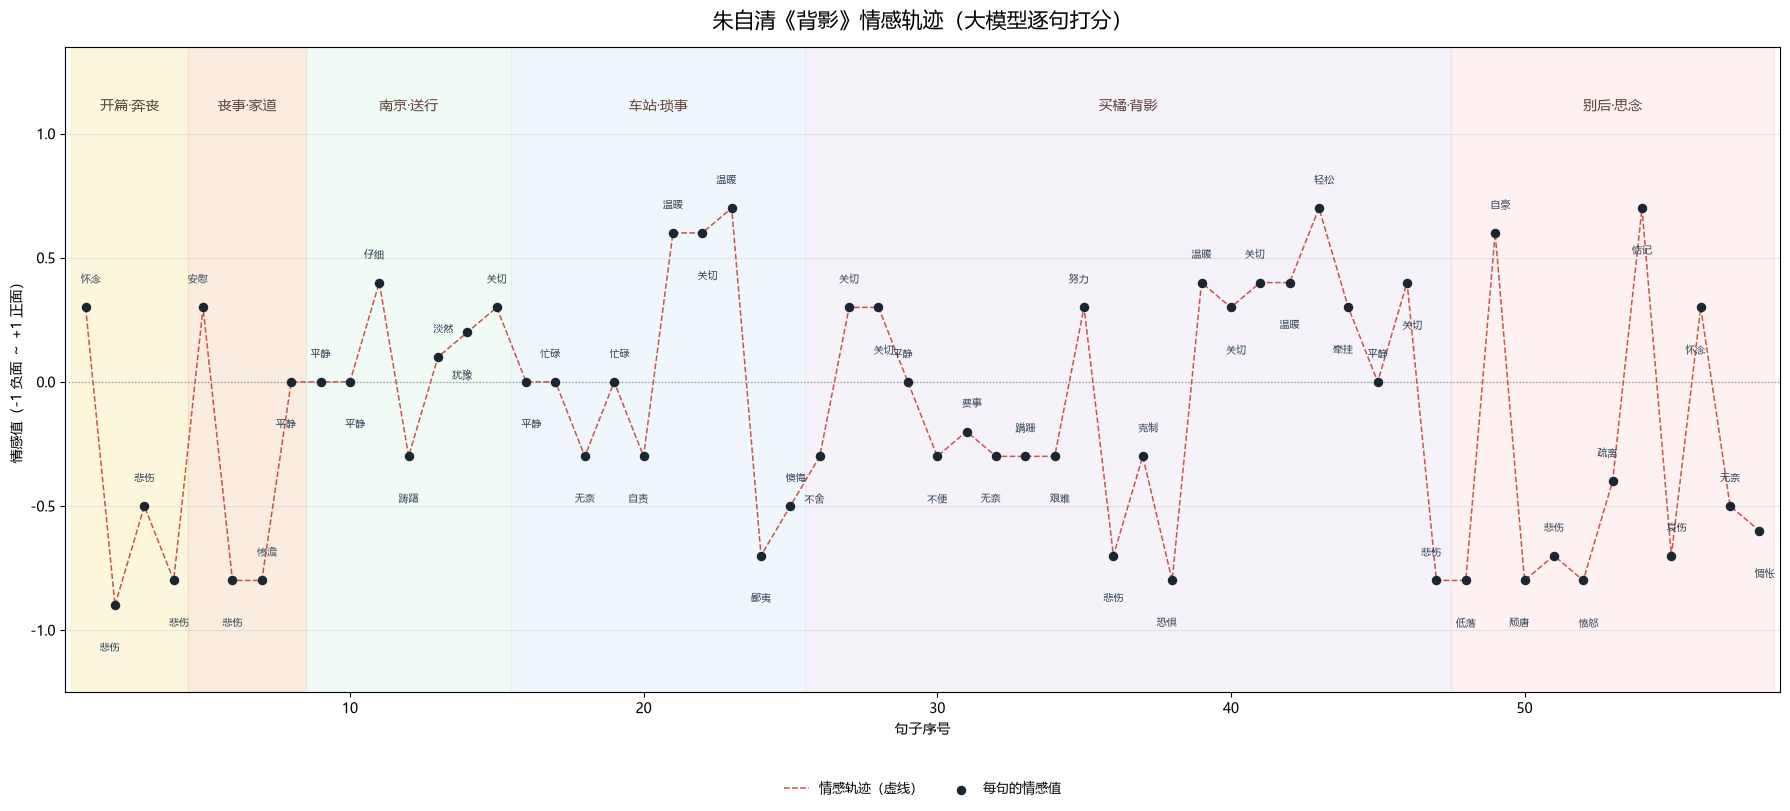

In [6]:
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Heiti TC", "Noto Sans CJK SC"]
rcParams["axes.unicode_minus"] = False

x = df["句子序号"].tolist()
y = df["情感值"].tolist()
labels = df["情感词"].tolist()

# 六个叙事段落（用于底色分区）
segments = [
    (1, 4, "开篇·奔丧", "#f9e79f"),
    (5, 8, "丧事·家道", "#f5cba7"),
    (9, 15, "南京·送行", "#d5f5e3"),
    (16, 25, "车站·琐事", "#d6eaf8"),
    (26, 47, "买橘·背影", "#e8daef"),
    (48, 58, "别后·思念", "#fadbd8"),
]

fig, ax = plt.subplots(figsize=(18, 8.2))
for a, b, name, color in segments:
    ax.axvspan(a - 0.5, b + 0.5, color=color, alpha=0.35, zorder=0)
    ax.text((a + b) / 2, 1.14, name, ha="center", va="top", fontsize=10, color="#5d4037")

ax.plot(x, y, color="#c0392b", linestyle="--", linewidth=1.1, alpha=0.85, zorder=2, label="情感轨迹（虚线）")
ax.scatter(x, y, color="#1b2631", s=34, zorder=3, label="每句的情感值")

# 每个点标注情感词，上下交替避免重叠
for i, (xi, yi, w) in enumerate(zip(x, y, labels)):
    dy = 0.09 if i % 2 == 0 else -0.15
    dx = 0.18 if i % 3 == 0 else (-0.18 if i % 3 == 1 else 0)
    ax.text(xi + dx, yi + dy, w, ha="center", va="bottom" if dy > 0 else "top",
            fontsize=7.2, color="#2c3e50", zorder=4)

ax.axhline(0, color="gray", linewidth=0.9, linestyle=":", alpha=0.8)
ax.set_xlim(0.3, 58.7)
ax.set_ylim(-1.25, 1.35)
ax.set_xlabel("句子序号")
ax.set_ylabel("情感值（-1 负面 ～ +1 正面）")
ax.set_title("朱自清《背影》情感轨迹（大模型逐句打分）", fontsize=15, pad=14)
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=9, frameon=False)
plt.tight_layout()
plt.savefig("背影情感轨迹.png", dpi=150, bbox_inches="tight")
plt.show()

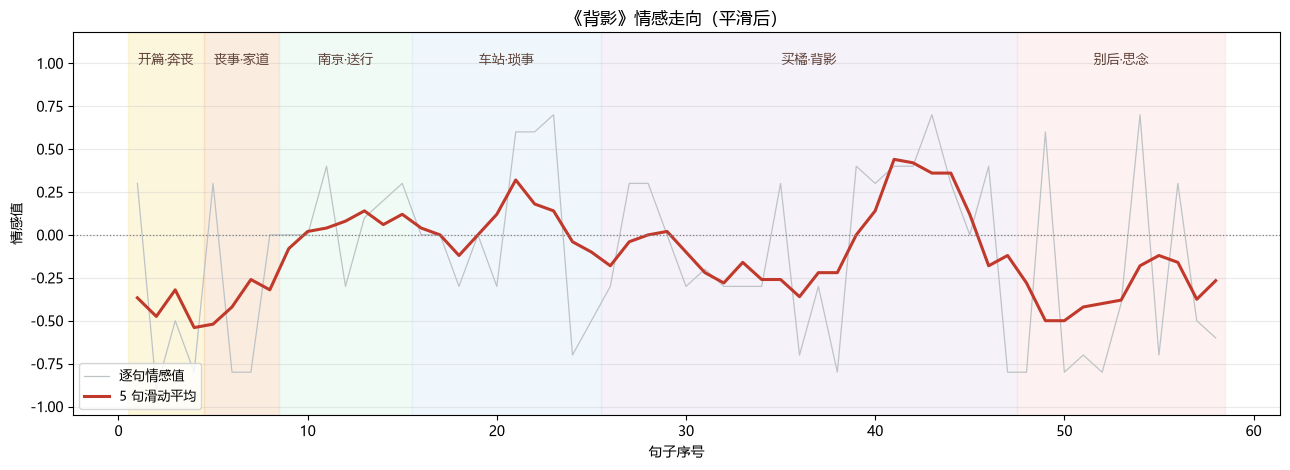

In [7]:
# 更平滑的趋势：5 句滑动平均（能看清"宏观情绪走向"）
df["平滑"] = df["情感值"].rolling(window=5, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(13, 4.8))
for a, b, name, color in segments:
    ax.axvspan(a - 0.5, b + 0.5, color=color, alpha=0.35, zorder=0)
    ax.text((a + b) / 2, 1.06, name, ha="center", va="top", fontsize=9, color="#5d4037")

ax.plot(df["句子序号"], df["情感值"], color="#bdc3c7", linewidth=0.9, label="逐句情感值")
ax.plot(df["句子序号"], df["平滑"], color="#c0392b", linewidth=2.2, label="5 句滑动平均")
ax.axhline(0, color="gray", linestyle=":", linewidth=0.9)
ax.set_ylim(-1.05, 1.18)
ax.set_xlabel("句子序号")
ax.set_ylabel("情感值")
ax.set_title("《背影》情感走向（平滑后）")
ax.legend(loc="lower left", fontsize=9)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("背影情感走向_平滑.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. 分段统计：情绪在哪里最低、哪里回暖？

In [8]:
rows = []
for a, b, name, _ in segments:
    part = df[(df["句子序号"] >= a) & (df["句子序号"] <= b)]
    low_word = part.loc[part["情感值"].idxmin(), "情感词"]
    high_word = part.loc[part["情感值"].idxmax(), "情感词"]
    rows.append({
        "段落": name,
        "句号范围": f"{a}–{b}",
        "句数": len(part),
        "平均情感值": round(part["情感值"].mean(), 2),
        "最低": round(part["情感值"].min(), 1),
        "最高": round(part["情感值"].max(), 1),
        "最低点情感词": low_word,
        "最高点情感词": high_word,
    })

df_seg = pd.DataFrame(rows)
df_seg

,段落,句号范围,句数,平均情感值,最低,最高,最低点情感词,最高点情感词
0,开篇·奔丧,1–4,4,-0.48,-0.9,0.3,悲伤,怀念
1,丧事·家道,5–8,4,-0.32,-0.8,0.3,悲伤,安慰
2,南京·送行,9–15,7,0.10,-0.3,0.4,踌躇,仔细
3,车站·琐事,16–25,10,0.01,-0.7,0.7,鄙夷,温暖
4,买橘·背影,26–47,22,-0.02,-0.8,0.7,恐惧,轻松
5,别后·思念,48–58,11,-0.34,-0.8,0.7,低落,惦记


In [9]:
# 全篇概况
print("全篇平均情感值：", round(df["情感值"].mean(), 3))
print("最低：", df.loc[df["情感值"].idxmin(), "句子序号"], "句", df["情感值"].min(), df.loc[df["情感值"].idxmin(), "情感词"])
print("最高：", df.loc[df["情感值"].idxmax(), "句子序号"], "句", df["情感值"].max(), df.loc[df["情感值"].idxmax(), "情感词"])
print("负面句（<0）占比：", f'{(df["情感值"] < 0).mean():.0%}')
print("\n出现最多的情感词：")
print(df["情感词"].value_counts().head(8))

全篇平均情感值： -0.114
最低： 2 句 -0.9 悲伤
最高： 23 句 0.7 温暖
负面句（<0）占比： 48%

出现最多的情感词：
情感词
悲伤    7
关切    7
平静    6
温暖    4
无奈    3
怀念    2
忙碌    2
安慰    1
Name: count, dtype: int64


## 5. 和大模型比一比：SnowNLP 读得懂《背影》吗？

用 SnowNLP 对同样的 58 句逐句打分，把它的 $[0,1]$ 正面概率线性映射到 $[-1,1]$，再与大模型对比。

In [10]:
from snownlp import SnowNLP
import numpy as np

df["SnowNLP原始"] = [SnowNLP(s).sentiments for s in df["句子"]]
df["SnowNLP映射"] = df["SnowNLP原始"] * 2 - 1

r = np.corrcoef(df["情感值"], df["SnowNLP映射"])[0, 1]
print(f"大模型 vs SnowNLP 的皮尔逊相关系数：r = {r:.3f}")
print("大模型均值：", round(df["情感值"].mean(), 3), "| SnowNLP 映射后均值：", round(df["SnowNLP映射"].mean(), 3))

df[["句子序号", "句子清洗", "情感值", "SnowNLP原始", "SnowNLP映射"]].head(8)

大模型 vs SnowNLP 的皮尔逊相关系数：r = -0.268
大模型均值： -0.114 | SnowNLP 映射后均值： 0.169


,句子序号,句子清洗,情感值,SnowNLP原始,SnowNLP映射
0,1,我与父亲不相见已二年余了，我最不能忘记的是他的背影。,0.3,0.977274,0.954549
1,2,那年冬天，祖母死了，父亲的差使也交卸了，正是祸不单行的日子。,-0.9,0.951999,0.903998
2,3,我从北京到徐州，打算跟着父亲奔丧回家。,-0.5,0.971389,0.942778
3,4,到徐州见着父亲，看见满院狼藉的东西，又想起祖母，不禁簌簌地流下眼泪。,-0.8,0.998988,0.997977
4,5,父亲说：“事已如此，不必难过，好在天无绝人之路！,0.3,0.959723,0.919446
5,6,回家变卖典质，父亲还了亏空；又借钱办了丧事。,-0.8,0.840948,0.681896
6,7,这些日子，家中光景很是惨澹，一半为了丧事，一半为了父亲赋闲。,-0.8,0.989523,0.979046
7,8,丧事完毕，父亲要到南京谋事，我也要回北京念书，我们便同行。,0.0,0.906061,0.812121


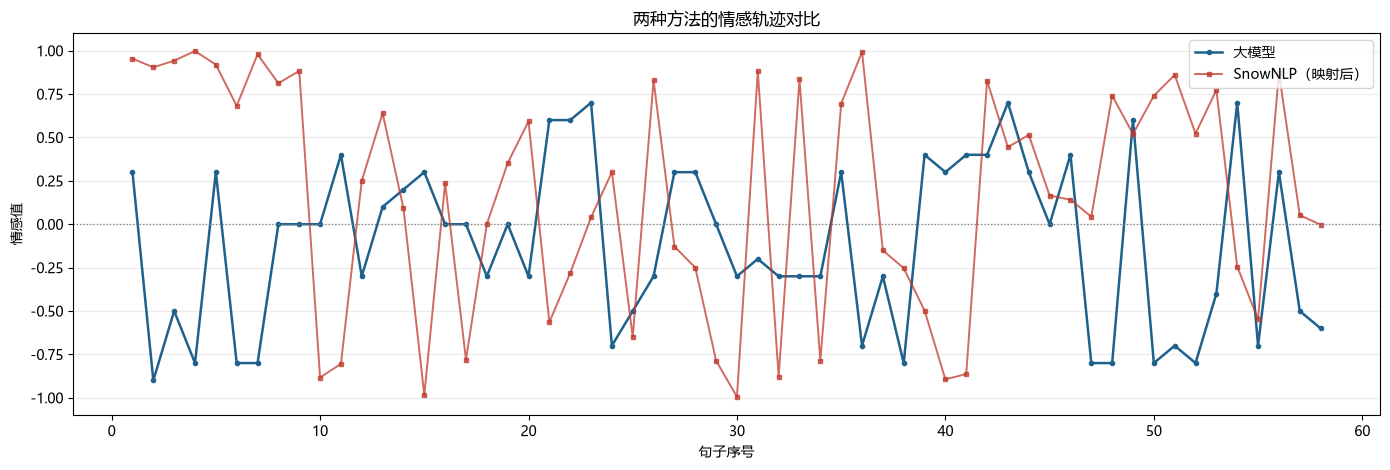

In [11]:
fig, ax = plt.subplots(figsize=(14, 4.8))
ax.plot(df["句子序号"], df["情感值"], color="#1f618d", linewidth=1.8, marker="o", markersize=3, label="大模型")
ax.plot(df["句子序号"], df["SnowNLP映射"], color="#c0392b", linewidth=1.4, marker="s", markersize=3, alpha=0.75, label="SnowNLP（映射后）")
ax.axhline(0, color="gray", linestyle=":", linewidth=0.9)
ax.set_ylim(-1.1, 1.1)
ax.set_xlabel("句子序号")
ax.set_ylabel("情感值")
ax.set_title("两种方法的情感轨迹对比")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("背影_两种方法对比.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
# 分歧最大的 5 句：看看 SnowNLP 错在哪里
df["分歧"] = (df["情感值"] - df["SnowNLP映射"]).abs()
big = df.sort_values("分歧", ascending=False).head(5)
big[["句子序号", "句子清洗", "情感值", "SnowNLP映射"]]

,句子序号,句子清洗,情感值,SnowNLP映射
1,2,那年冬天，祖母死了，父亲的差使也交卸了，正是祸不单行的日子。,-0.9,0.903998
3,4,到徐州见着父亲，看见满院狼藉的东西，又想起祖母，不禁簌簌地流下眼泪。,-0.8,0.997977
6,7,这些日子，家中光景很是惨澹，一半为了丧事，一半为了父亲赋闲。,-0.8,0.979046
35,36,这时我看见他的背影，我的泪很快地流下来了。,-0.7,0.993078
50,51,他触目伤怀，自然情不能自已。,-0.7,0.860162


## 6. 情感轨迹解读

把六个段落连起来看，是一条典型的"**悲—暖—更悲**"的曲线：

1. **开篇·奔丧（1–4 句，均值 −0.48）**：祖母去世、父亲失业、满院狼藉，"悲伤/怀念"一路走低，
   第 2 句"祖母死了"（−0.9）是全篇最低点，第 4 句"不禁簌簌地流下眼泪"（−0.8）与之连成第一个低谷。
   开篇第一句"我最不能忘记的是他的背影"是"怀念"（+0.3），说明回忆本身带着温度。
2. **丧事·家道（5–8 句，均值 −0.33）**：变卖典质、光景惨澹，"惨澹""悲伤"延续低沉，
   但父亲一句"事已如此，不必难过，好在天无绝人之路"被读成"安慰"（+0.3），露出父亲的担当。
3. **南京·送行（9–15 句，均值 +0.10）**：情绪第一次**转暖**。"仔细""关切"反复出现，
   父亲再三嘱咐茶房、终于决定亲自送"我"，琐碎里全是牵挂。
4. **车站·琐事（16–25 句，均值 +0.01）**：表面平淡，其实暗流涌动。
   "我"嫌父亲说话不漂亮、暗笑他的迂（"鄙夷"−0.7），随后又自责"我那时真是太聪明了"（"懊悔"−0.5）——
   **儿子的不耐烦与事后的悔意**，是全文最真实的一层情感。
5. **买橘·背影（26–47 句，均值 −0.02）**：情绪最密集、起伏最大的一段，也是全文高潮。
   父亲蹒跚攀爬月台（"艰难"−0.3、"努力"+0.3），"我看见他的背影，我的泪很快地流下来了"（"悲伤"−0.7）；
   买到橘子后"心里很轻松似的"（"轻松"+0.7），离别时"进去吧，里边没人"（"关切"+0.4）。
   **同一条段里，心疼、感动、不舍交替出现**，平均分接近 0，但这是"悲喜交加"的 0，不是"无感"的 0。
6. **别后·思念（48–58 句，均值 −0.34）**：父亲老境颓唐、触目伤怀，"低落""颓唐""愤怒""疏离"层层压低；
   结尾读到父亲"大约大去之期不远矣"，"哀伤"（−0.7）与"惆怅"（−0.6）收束全篇，最后一句"我不知何时再能与他相见"是绵长的思念。

**一句话**：整体均值 −0.11 看起来"接近中性"，但这是**剧烈起伏后的平均**——
《背影》的情感不是"平"，而是"压着写"：越是不动声色，越见其重。
这也说明：**只看全篇平均分会严重误读文学作品，必须看轨迹和分段。**

## 7. 大模型 vs SnowNLP：为什么差别这么大？

**相关系数 $r \\approx -0.27$**——两者不仅不一致，甚至**方向相反**。原因很具体：

| 句子 | 大模型 | SnowNLP | 问题 |
|---|---|---|---|
| 2. 那年冬天，祖母死了，父亲的差使也交卸了…… | −0.9 | **+0.9** | "死了"被当成中性/正面，"交卸"没识别出失业 |
| 4. ……又想起祖母，不禁簌簌地流下眼泪 | −0.8 | **+1.0** | 只看到"想起""眼泪"里的中性词形 |
| 36. 这时我看见他的背影，我的泪很快地流下来了 | −0.7 | **+1.0** | 把"流泪"当成正面情绪 |
| 51. 他触目伤怀，自然情不能自已 | −0.7 | **+0.9** | 文言色彩浓，通用语料覆盖不到 |

SnowNLP 是**在购物评论上训练的通用情感分类器**，它的"世界"里：
"眼泪""想起""背影"都不算负面，反而常和好评一起出现。
而《背影》是 1925 年的白话散文，**文言残留 + 克制抒情 + 大量动作细节**，
恰好是词袋模型最不擅长的文本。

大模型则能结合上下文推断：祖母去世 → 悲伤；父亲攀爬月台 → 心疼；"我那时真是太聪明了" → 反讽式自责。
它甚至能读出"心里很轻松似的"背后的**如释重负**（+0.7），而不是字面的"轻松"。

**结论**：对文学作品这种"情感藏在叙事里"的文本，
传统词典/分类器基本不可用，**大模型是目前更合适的选择**；但它也会过度解读（见第 8 节）。

## 8. 局限与反思

1. **"情感词"未必是原文的词。** 提示词允许"提取或生成"，所以出现了"怀念""关切""自责"等**概括词**，
   它们不是《背影》里的原词，而是模型对句子的**归纳**。这对"情感轨迹"有帮助，但不适合做"词频统计"。
2. **逐句打分有上下文损失。** 《背影》大量句子单独看是中性的（"我们过了江，进了车站"），
   模型只能给 0；真正的情绪要靠前后句累积。
3. **模型会"过度抒情"。** 把"我的泪很快地流下来了"打成 −0.7 是合理的，但把某些平淡叙事也读出情绪，
   就属于过度解读——**文学分析应保留人的判断**。
4. **可复现性**：temperature=0.3 下同一句多次运行结果可能不同，本作业固定了缓存结果。
5. **版权与引用**：`背影.txt` 为教学用文本，朱自清《背影》已进入公有领域。

## 9. 小结

- 按 PPT 的四步完成了"分句 → 大模型抽情感词/打分 → 情感轨迹图"的完整链路；
- 58 句全部拿到了情感词与情感值，画出了带标签的虚线轨迹图，并做了分段统计与平滑趋势；
- 发现《背影》的情感结构是"**悲—暖—悲**"：奔丧最悲，南京送行回暖，买橘背影悲喜交加，结尾思念绵长；
- 与 SnowNLP 对比（$r \\approx -0.27$）实证了传统方法在文学作品上的失效，说明**大模型更适合"读懂"这类文本**；
- 生成文件：`背影情感轨迹.png`、`背影情感走向_平滑.png`、`背影_两种方法对比.png`、`程序4_背影_大模型结果.json`。